# Exploration du dataset MNIST

Ce notebook a pour objectif d'explorer le jeu de données MNIST avant toute phase de omdélisation.

Objectifs :

*   Charger le dataset ;
*   Vérifier sa structure ;
*   Visualiser plusieurs exemples ;
*   Étudier la répartition des classes ;
*   Préparer les données pour les modèles de Machine Learning et Deep Learning.

# Configuration de l'environnement

Afin de garantir la reproductibilité des expériences, une graine aléatoire fixe est utilisée.

In [2]:
SEED = 42

In [11]:
import random

import matplotlib.pyplot as plt
import numpy as np
import tensorflow as tf
from tensorflow.keras.datasets import mnist

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("Seed fixée :", SEED)

Seed fixée : 42


# Chargement du dataset MNIST

Le dataset est chargé depuis Tensorflow/Keras.

La base MNIST contient : 

*   60 000 images d'entraînement ;
*   10 000 images de test ;
*   des images de taille 28 x 28 pixels ;
*   10 classes correspondant aux chiffres de 0 à 9.

In [5]:
(x_train_full, y_train_full), (x_test, y_test) = mnist.load_data()

# Vérification de la structure des données

Nous vérifions les dimensions des ensembles d'entraînement et de test

In [6]:
print("Train :", x_train_full.shape)
print("Labels train :", y_train_full.shape)

print("Test :", x_test.shape)
print("Labels test :", y_test.shape)

Train : (60000, 28, 28)
Labels train : (60000,)
Test : (10000, 28, 28)
Labels test : (10000,)


# Vérification des classes présentes

L'objectif est de s'assurer que les dix chiffres sont bien représentés dans le dataset. 

In [7]:
print("Classes présentes :", np.unique(y_train_full))

Classes présentes : [0 1 2 3 4 5 6 7 8 9]


# Conclusion intermédiaire

Le chargement du dataset s'est effectué correctement.

Observations :

- 60 000 images d'entraînement ;
- 10 000 images de test ;
- dimensions conformes (28 × 28) ;
- présence des 10 classes attendues.

Le dataset est prêt pour l'étape suivante : la visualisation et l'analyse exploratoire des images.

# Vérification du nombre d'exemples

Nous vérifions le nombre d'images présentes dans cahque ensemble afin de confirmer la conformité du dataset avec sa documentation.

In [8]:
print(f"Nombre d'images d'entraînement : {len(x_train_full)}")
print(f"Nombre de labels d'entraînement : {len(y_train_full)}")

print(f"Nombre d'images de test : {len(x_test)}")
print(f"Nombre de labels de test : {len(y_test)}")

Nombre d'images d'entraînement : 60000
Nombre de labels d'entraînement : 60000
Nombre d'images de test : 10000
Nombre de labels de test : 10000


# Vérification des labels

Nous vérifions que les labels associés aux images correspondent bien aux chiffres attendus.

In [10]:
print("Premiers labels d'entraînement :")
print(y_train_full[:20])

print("Classe minimale :", y_train_full.min())
print("Classe maximale :", y_train_full.max())

Premiers labels d'entraînement :
[5 0 4 1 9 2 1 3 1 4 3 5 3 6 1 7 2 8 6 9]
Classe minimale : 0
Classe maximale : 9


# Conclusion DATA-01

Le dataset MNIST a été chargé avec succès.

Vérifications réalisées :

- 60 000 images d'entraînement ;
- 10 000 images de test ;
- dimensions des images : 28 × 28 pixels ;
- présence des 10 classes (0 à 9) ;
- cohérence entre les images et leurs labels.

Le dataset est conforme à la documentation officielle et prêt pour l'analyse exploratoire.

# Visualisation des classes

Afin de mieux comprendre le contenu du dataset, nous affichons un exemple représentatif de cahcun des dix calsses présetnes dans MNIST.

Cette visualisation permettra de vérifier visuellement la diversité des chiffres manuscrits.

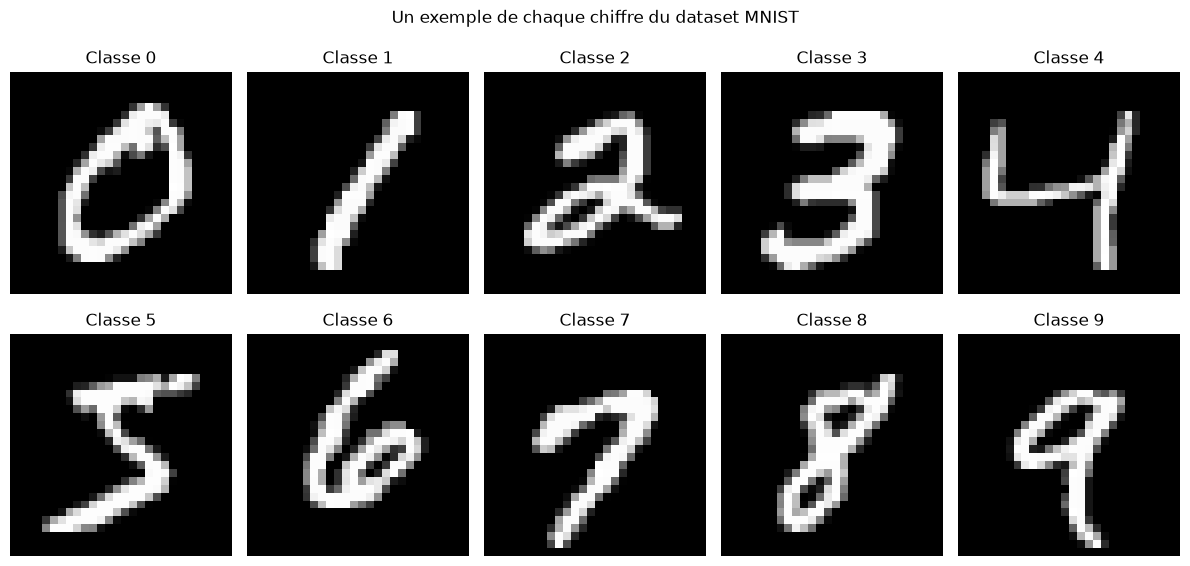

In [13]:
fig, axes = plt.subplots(2, 5, figsize=(12, 6))

for digit in range(10):
    idx = np.where(y_train_full == digit)[0][0]

    ax = axes[digit // 5, digit % 5]
    ax.imshow(x_train_full[idx], cmap="gray")
    ax.set_title(f"Classe {digit}")
    ax.axis("off")

plt.suptitle("Un exemple de chaque chiffre du dataset MNIST")
plt.tight_layout()
plt.savefig("../reports/figures/mnist_classes_examples.png", bbox_inches="tight")
plt.show()

# Analyse

Cette première visualisation montre que :

- les dix classes sont bien présentes ;
- les chiffres sont centrés dans l'image ;
- les écritures manuscrites présentent déjà une certaine variabilité ;
- certaines classes semblent plus ambiguës que d'autres (par exemple 4, 5 ou 9 selon l'écriture).

Ces observations justifient l'utilisation de modèles capables d'extraire automatiquement des caractéristiques visuelles pertinentes.

# Variabilité intra-classe

Nous observons plusieurs exemples de cahque chiffre afin d'évaluer la diversité des écritures manuscrites. 

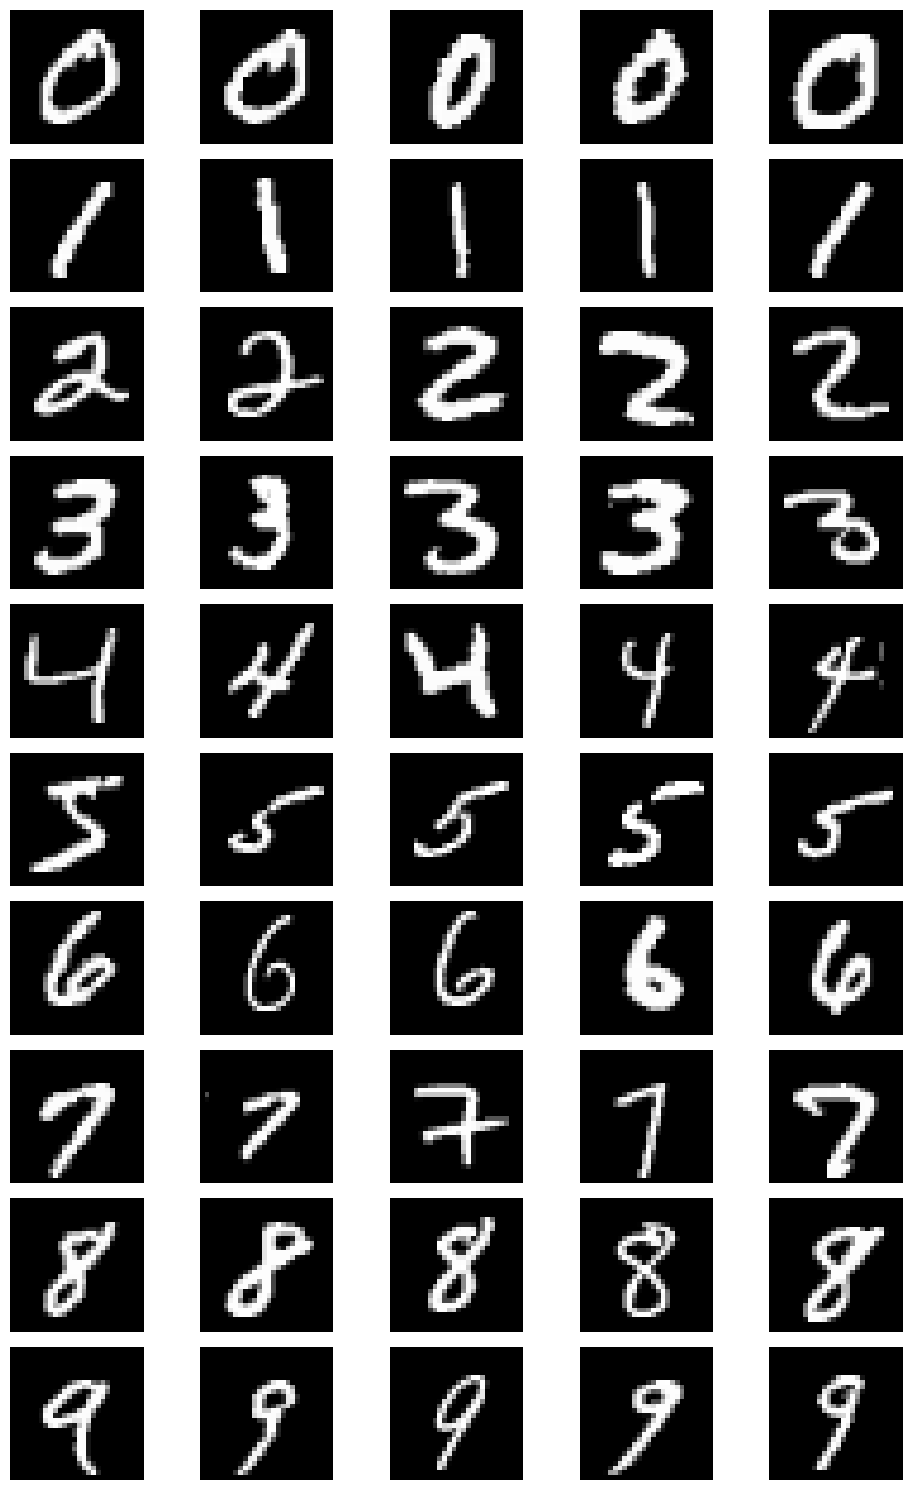

In [16]:
fig, axes = plt.subplots(10, 5, figsize=(10, 15))

for digit in range(10):
    indices = np.where(y_train_full == digit)[0][:5]

    for col, idx in enumerate(indices):
        axes[digit, col].imshow(x_train_full[idx], cmap="gray")

        if col == 0:
            axes[digit, col].set_ylabel(f"{digit}", rotation=0, labelpad=20)

        axes[digit, col].axis("off")

plt.tight_layout()
plt.savefig(
    "../reports/figures/mnist_classes_variability_examples.png", bbox_inches="tight"
)
plt.show()

# Analyse

L'affichage de plusieurs exemples par classe met en évidence une diversité visuelle des chiffres manuscrits.

On observe notamment :

- des épaisseurs de trait différentes ;
- des styles d'écriture variés selon les individus ;
- des légères variations d'inclinaison ;
- des différences de proportions et de centrage.

Cette observation reste qualitative puisqu'elle repose uniquement sur un sous-ensemble d'exemples du dataset.

Une étude quantitative de la variabilité nécessiterait des mesures statistiques ou des techniques de visualisation plus avancées.

# Conclusion DATA-02

Les dix classes du dataset ont été visualisées avec succès.

Les observations montrent :

- une bonne qualité générale des images ;
- une variabilité naturelle des écritures manuscrites ;
- la présence de formes parfois ambiguës pouvant conduire à certaines erreurs de classification.

L'étape suivante consiste à vérifier quantitativement la répartition des classes dans le dataset.